# ДЗ 4. Матрицы в PyTorch: малоранговые представления

Тема про то, зачем вообще нужна матричная низкоранговость (не только "SVD раскладывает матрицу
на три" — а что с этим реально делать): сжатие данных и весов моделей, устранение шума,
рекомендательные системы, восстановление данных по неполным наблюдениям, устойчивое решение
плохо обусловленных систем.

Все задачи используют синтетические матрицы (не требуют скачивания, работают одинаково везде),
крупнейшая матрица в ДЗ — 2000×1500, вычисления занимают секунды.

In [22]:
import torch
import numpy as np
import matplotlib.pyplot as plt
torch.manual_seed(0)

## Уровень 1. Попроще

### Задача 1.1. SVD-сжатие изображения и теорема Эккарта-Юнга

Теорема Эккарта-Юнга утверждает: среди **всех** матриц ранга $\le k$ именно усечённое SVD
$A_k = U_k \Sigma_k V_k^\top$ даёт наименьшую ошибку приближения в норме Фробениуса, и эта ошибка
в точности равна $\|A - A_k\|_F = \sqrt{\sum_{i>k} \sigma_i^2}$ — сумме квадратов
**отброшенных** сингулярных чисел.

1. Постройте (или загрузите, например `scipy.datasets.face(gray=True)`) любое двумерное
   "изображение" — можно и синтетическое, если предпочитаете детерминированный пример.
2. Посчитайте SVD, постройте rank-$k$ приближение для нескольких $k$, убедитесь, что реальная
   ошибка **совпадает** (не приближённо, а с точностью до чисел с плавающей точкой) с
   теоретической формулой через хвост сингулярных чисел.
3. Экспериментально проверьте саму оптимальность: возьмите произвольную факторизацию
   $A \approx W_1 W_2$ ранга $k$ со случайной инициализацией, **дообучите** её градиентным
   спуском по той же метрике (норма Фробениуса ошибки), и убедитесь, что даже после оптимизации
   она не может превзойти ошибку SVD-усечения того же ранга.
4. Постройте график: ошибка приближения (и график compression ratio) от ранга $k$.

In [23]:
import scipy.datasets
import matplotlib.pyplot as plt
face = scipy.datasets.face(gray=True)

In [24]:
u, s, vh = np.linalg.svd(face, full_matrices=False)

Корень от суммы квадратов отброшенных сингулярных чисел: 9323.917398370178
Норма фробениуса разности A и A_k: 9323.917398370175


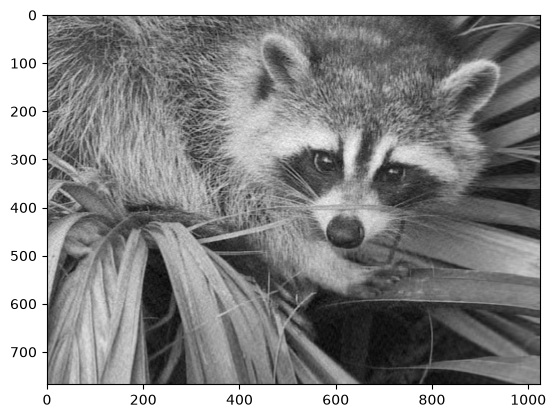

In [25]:
k = 100
least_loss = np.linalg.norm(s[k:])
print("Корень от суммы квадратов отброшенных сингулярных чисел:", least_loss)

restored_face = u[:, :k]@np.diag(s[:k])@vh[:k,:]

real_loss = np.linalg.norm(face-restored_face)

print("Норма фробениуса разности A и A_k:", real_loss)

plt.imshow(restored_face, cmap='gray')
plt.show()

In [26]:
import torch.optim

device = torch.device("cuda")

m, n = face.shape

A1 = torch.randn(m, k, device = device, requires_grad=True)
A2 = torch.randn(k, n, device = device, requires_grad=True)
optimizer = torch.optim.Adam([A1, A2], lr = 0.01)
face_tens = torch.from_numpy(face).float().to(device)

for _ in range(5000):
    optimizer.zero_grad()
    loss = torch.linalg.norm(face_tens - A1 @ A2)
    loss.backward()
    optimizer.step()

print("Ошибка с SVD:", real_loss)

print("Ошибка с градиентным спуском:", loss.item())

Ошибка с SVD: 9323.917398370175
Ошибка с градиентным спуском: 9323.9208984375


### Задача 1.2. Восстановление зашумлённой low-rank матрицы (денойзинг через усечение)

Возьмите матрицу с известной низкоранговой структурой ($M = UV$, ранг $r$), добавьте гауссов шум
на **все** элементы, и попробуйте восстановить исходную чистую матрицу truncated SVD.

1. Постройте `noisy = clean + шум`.
2. Для каждого $k = 1, \ldots, \min(m,n)$ посчитайте ошибку rank-$k$ приближения `noisy`
   **относительно `clean`** (не относительно `noisy`!) — это ключевое отличие от задачи 1.1.
3. Найдите $k^*$, минимизирующий эту ошибку, и сравните с истинным рангом $r$.
4. Сравните лучший достижимый truncation-денойзинг с "неусечённой" зашумлённой матрицей (то есть
   $k=\min(m,n)$, эквивалентно вообще не денойзить).

In [27]:
# TODO: денойзинг через усечение SVD, поиск оптимального k
m, n, r = 1000, 1000, 10

U = torch.normal(mean=0.0, std=5.0, size=(m, r))
V = torch.normal(mean=0.0, std=5.0, size=(r, n))
M = U @ V
noise = torch.randn(m, n)
noisy = M + noise


In [28]:
u, s, vh = torch.linalg.svd(noisy, full_matrices=False)
hist = []
for k in range (1, min(m, n)+1):
    noisy_k = u[:, :k] @ torch.diag(s[:k]) @ vh[:k, :]
    loss = torch.linalg.norm(M - noisy_k)
    hist.append(loss)

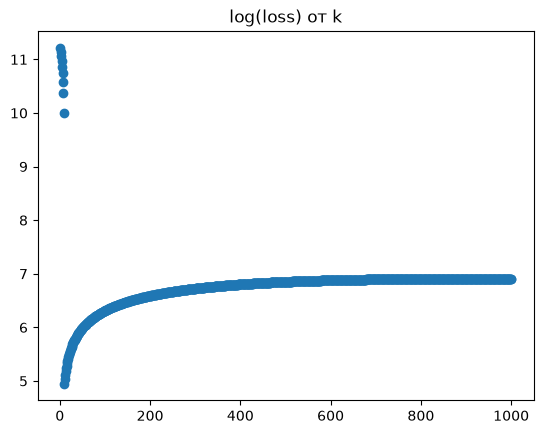

k* = 10
r = 10
loss при k* = 154.6581
loss изначальный = 999.7795


In [29]:
plt.scatter(np.arange(1, min(m, n)+1), np.log(hist))
plt.title("log(loss) от k")
plt.show()
k_star = np.argmin(hist)+1
print("k* =", k_star)
print("r =", r)
print("loss при k* =", np.round(hist[k_star].item(), 4))
loss_init = torch.linalg.norm(M - noisy)
print("loss изначальный =", np.round(loss_init.item(), 4))

### Задача 1.3. Плохая обусловленность и регуляризация через усечение SVD

Число обусловленности $\mathrm{cond}(A) = \sigma_{\max}/\sigma_{\min}$ показывает, во сколько раз
могут усилиться ошибки измерения при решении $Ax=b$. При большом числе обусловленности даже
крошечный шум в $b$ может привести к катастрофически неверному $x$.

1. Постройте искусственно плохо обусловленную матрицу $A = U\Sigma V^\top$ с сингулярными
   числами, убывающими от 1 до $10^{-12}$ (используйте `torch.logspace`).
2. Возьмите $x_{true}$, лежащий **строго в подпространстве**, натянутом на первые $k_{true}=10$
   правых сингулярных векторов (а не произвольный случайный вектор!) — так, чтобы у задачи
   в принципе была шанс на точное восстановление.
3. Постройте $b = Ax_{true}$, добавьте небольшой шум измерения к $b$ (например, $10^{-6}$).
4. Сравните: (а) наивное решение через `torch.linalg.solve(A, b_noisy)`; (б) решения через
   усечённую псевдообратную с разным числом сохранённых сингулярных направлений $k$.
5. Постройте график ошибки от $k$ и объясните его форму.

In [30]:
# TODO: плохо обусловленная система, наивное решение vs усечённая псевдообратная
n = 200
U, _ = torch.linalg.qr(torch.randn(n, n))
V, _ = torch.linalg.qr(torch.randn(n, n))
s = torch.logspace(0, -12, steps=n)
A = U @ torch.diag(s) @ V.T
cond_A = torch.linalg.cond(A)
print('Число обусловленности:', torch.round(cond_A, decimals=4).item())

Число обусловленности: 5589522432.0


In [31]:
k_true = 10
coeffs = torch.randn(k_true, 1)
x_true = V[:, :k_true] @ coeffs
b = A @ x_true
b_noisy = b + 1e-6* torch.randn(n, 1)
x_noisy = torch.linalg.solve(A, b_noisy)
loss = torch.linalg.norm(x_true - x_noisy)
print("torch.linalg.solve() loss:", np.round(loss.item(), 4))

torch.linalg.solve() loss: 32790.5781


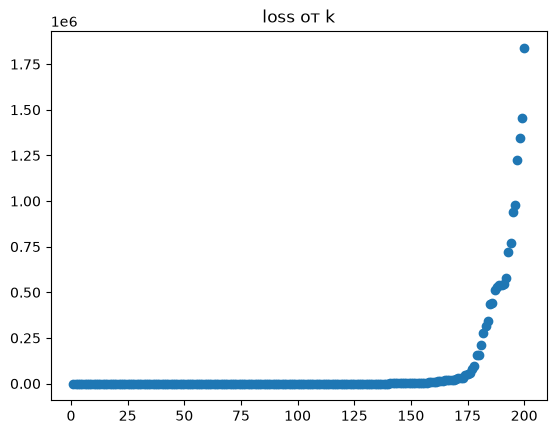

In [32]:
hist = []

for k in range(1, n + 1):
    U_k = U[:, :k]
    s_k = s[:k]
    V_k = V[:, :k]
    x_k = V_k @ torch.diag(1.0 / s_k) @ U_k.T @ b_noisy
    loss = torch.norm(x_k - x_true)
    hist.append(loss)
plt.scatter(np.arange(1, n+1), hist)
plt.title("loss от k")
plt.show()

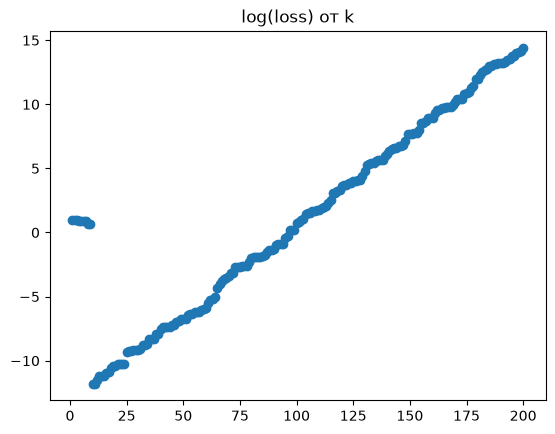

In [33]:
plt.scatter(np.arange(1, n+1), np.log(hist))
plt.title("log(loss) от k")
plt.show()

In [34]:
hist[5:15]

[tensor(2.4373),
 tensor(2.4319),
 tensor(2.0031),
 tensor(1.9928),
 tensor(7.6148e-06),
 tensor(7.5982e-06),
 tensor(1.0272e-05),
 tensor(1.3301e-05),
 tensor(1.3851e-05),
 tensor(1.4254e-05)]

Ошибка как раз становится близка к нулю когда мы берем ранг 10, что видно по последнему выводу, потому что x true натянут на первые 10 векторов. В конце график возрастает, так как появляются слишком маленькие сингулярные значения, мы на них делим и получаем, что огромное число умножается на шум.

## Уровень 2. Посложнее

### Задача 2 (★). Randomized SVD для больших матриц

Полное SVD стоит $O(\min(mn^2, m^2n))$ — дорого для больших матриц, даже если реально нужны
только первые $k \ll \min(m,n)$ сингулярных векторов. **Randomized SVD** (Halko, Martinsson,
Tropp, 2011) находит хорошее приближение top-$k$ SVD намного дешевле, используя случайную
проекцию.

1. Реализуйте `randomized_svd(A, k, n_oversample, n_iter)`:
   - Спроецируйте `A` на случайное подпространство: `Y = A @ Omega`, где `Omega` — случайная
     матрица размера `(n, k + n_oversample)`.
   - Улучшите качество подпространства несколькими **степенными итерациями**:
     `Y = A @ (A.T @ Y)` — это усиливает "сигнальные" направления относительно шумовых.
   - Постройте ортонормированный базис `Q` через `torch.linalg.qr(Y)`.
   - Спроецируйте задачу в это подпространство: `B = Q.T @ A` (маленькая матрица!), сделайте
     точное SVD от `B`, "поднимите" левые сингулярные векторы обратно: `U = Q @ U_B`.
2. Сравните на матрице $2000 \times 1500$ с истинным рангом 30 (плюс небольшой шум): скорость и
   точность (по сравнению с полным `torch.linalg.svd`) для первых 30 сингулярных чисел/векторов.

In [35]:
# TODO: randomized_svd + сравнение с полным SVD по скорости и точности

---
**Что сдавать:** ноутбук с реализованными функциями, графиками и письменными ответами на вопросы
для решённых задач. Все вычисления в сумме занимают на CPU не больше пары минут (самая тяжёлая
операция — полное SVD матрицы 2000×1500 в задаче 3.1, около секунды).